# 01 · Exploratory data analysis

**Input:** `data/processed/trips_clean.parquet` (built by `python -m src.data.build_dataset`; see `data/DATA_CARD.md`).
**Output:** the plots below, also saved to `figures/eda/`.

Questions:
1. What does SoC look like over a trip, and can it be trusted?
2. How does energy consumption depend on **speed**, **ambient temperature** and **road grade**?
3. How noisy is SoC-based consumption over short distances? (This matters for the Phase 2 target.)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.data.distance_bins import distance_bins
from src.data.load import SAMPLE_PERIOD_S

FIG_DIR = ROOT / "figures" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 2)

# Colours: validated categorical pair (slot 1 blue, slot 2 orange) + recessive chrome
SERIES_COLOR = {"A": "#2a78d6", "B": "#eb6834"}
SERIES_LABEL = {"A": "A · summer", "B": "B · winter"}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "text.color": "#0b0b0b", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "figure.dpi": 110,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})

clean = pd.read_parquet(ROOT / "data" / "processed" / "trips_clean.parquet")
bins = distance_bins(clean, bin_km=1.0)
print(f"{len(clean):,} samples, {clean.trip_id.nunique()} trips -> {len(bins):,} one-km bins "
      f"({bins.series.value_counts().to_dict()})")

1,040,099 samples, 70 trips -> 1,306 one-km bins ({'B': 757, 'A': 549})


## 1. SoC over a trip

Four contrasting trips, picked by rule (not by eye): the shortest and the longest summer trip, the longest winter
trip, and the winter trip with a charging stop. The dashed line is SoC **re-computed from battery current alone**
(coulomb counting: start SoC minus integrated amp-hours / 0.617 Ah per %-point, the ratio found in the data card).
If the two lines agree, the BMS SoC is essentially integrated current, and we can trust its *changes*.

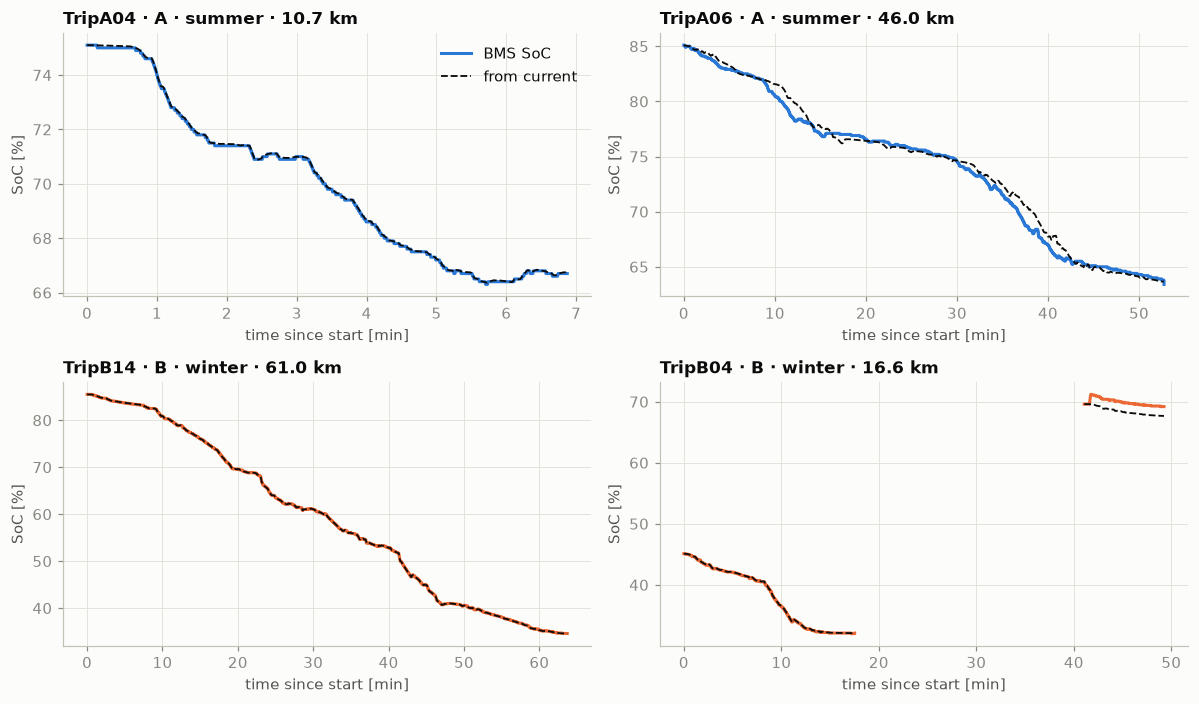

max |BMS SoC - coulomb SoC| per trip segment: median 0.08, 90th pct 0.10, max 4.42 %-points


In [2]:
AH_PER_PCT = 0.617  # from data/DATA_CARD.md (coulomb-counting check)
dur = clean.groupby("trip_id").agg(series=("series", "first"), n=("time_s", "size"), segs=("segment", "nunique"))
picks = [
    dur[dur.series == "A"].n.idxmin(), dur[dur.series == "A"].n.idxmax(),
    dur[dur.series == "B"].n.idxmax(), dur[dur.segs > 1].index[0],
]

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharey=False)
for ax, tid in zip(axes.flat, picks):
    t = clean[clean.trip_id == tid]
    color = SERIES_COLOR[t.series.iat[0]]
    for seg, s in t.groupby("segment"):
        minutes = s.time_s / 60
        coulomb = s.soc_pct.iat[0] + (s.battery_current_a * SAMPLE_PERIOD_S).cumsum() / 3600 / AH_PER_PCT
        ax.plot(minutes, s.soc_pct, color=color, label="BMS SoC" if seg == 0 else None)
        ax.plot(minutes, coulomb, color="#0b0b0b", lw=1.2, ls="--", label="from current" if seg == 0 else None)
    km = t.distance_km.max()
    ax.set_title(f"{tid} · {SERIES_LABEL[t.series.iat[0]]} · {km:.1f} km")
    ax.set_xlabel("time since start [min]"); ax.set_ylabel("SoC [%]")
axes.flat[0].legend(loc="upper right")
fig.tight_layout(); fig.savefig(FIG_DIR / "soc_over_trips.png", bbox_inches="tight")
plt.show()

err = []
for (tid, seg), s in clean.groupby(["trip_id", "segment"]):
    coulomb = s.soc_pct.iat[0] + (s.battery_current_a * SAMPLE_PERIOD_S).cumsum() / 3600 / AH_PER_PCT
    err.append((s.soc_pct - coulomb).abs().max())
print(f"max |BMS SoC - coulomb SoC| per trip segment: median {np.median(err):.2f}, "
      f"90th pct {np.quantile(err, 0.9):.2f}, max {np.max(err):.2f} %-points")

## 2. Consumption per kilometre

Each trip is cut into consecutive 1 km stretches (`src/data/distance_bins.py`). For each stretch, consumption is
the **battery energy drawn** (integrated `power_draw_kw`) divided by distance, in kWh/100 km. Regeneration counts
negatively, so a downhill kilometre can come out below zero.

Caveat: bins are distance-weighted, so fast driving (more km per minute) is over-represented compared with time.

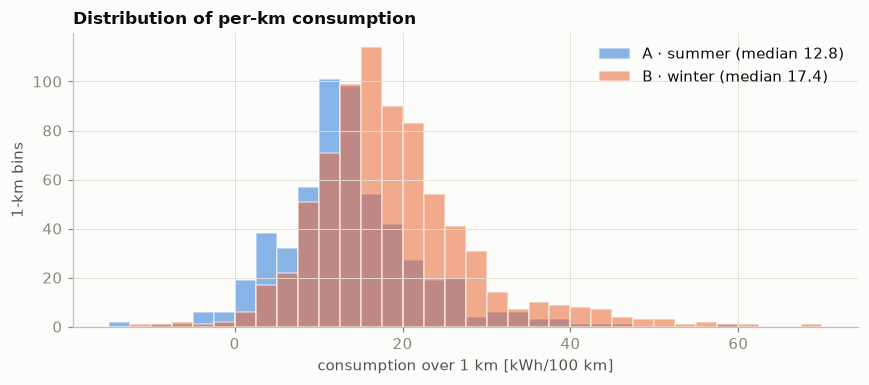

,kwh_per_100km,speed_mean_kmh,ambient_temp_c,heater_kw,grade_pct
series,,,,,
A,12.82,62.16,23.37,0.11,0.00
B,17.38,73.21,5.19,1.25,0.02


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
edges = np.arange(-15, 72, 2.5)
for s in ["A", "B"]:
    v = bins.loc[bins.series == s, "kwh_per_100km"]
    ax.hist(v, bins=edges, color=SERIES_COLOR[s], alpha=0.55, label=f"{SERIES_LABEL[s]} (median {v.median():.1f})",
            edgecolor="#fcfcfb", linewidth=1)
ax.set_xlabel("consumption over 1 km [kWh/100 km]"); ax.set_ylabel("1-km bins")
ax.set_title("Distribution of per-km consumption"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "consumption_hist.png", bbox_inches="tight"); plt.show()

bins.groupby("series")[["kwh_per_100km", "speed_mean_kmh", "ambient_temp_c", "heater_kw", "grade_pct"]].median()

### 2a. Consumption vs. speed, temperature, grade

Dots are individual 1-km bins; lines are the median within each x-bin (only bins with ≥ 10 points are drawn).

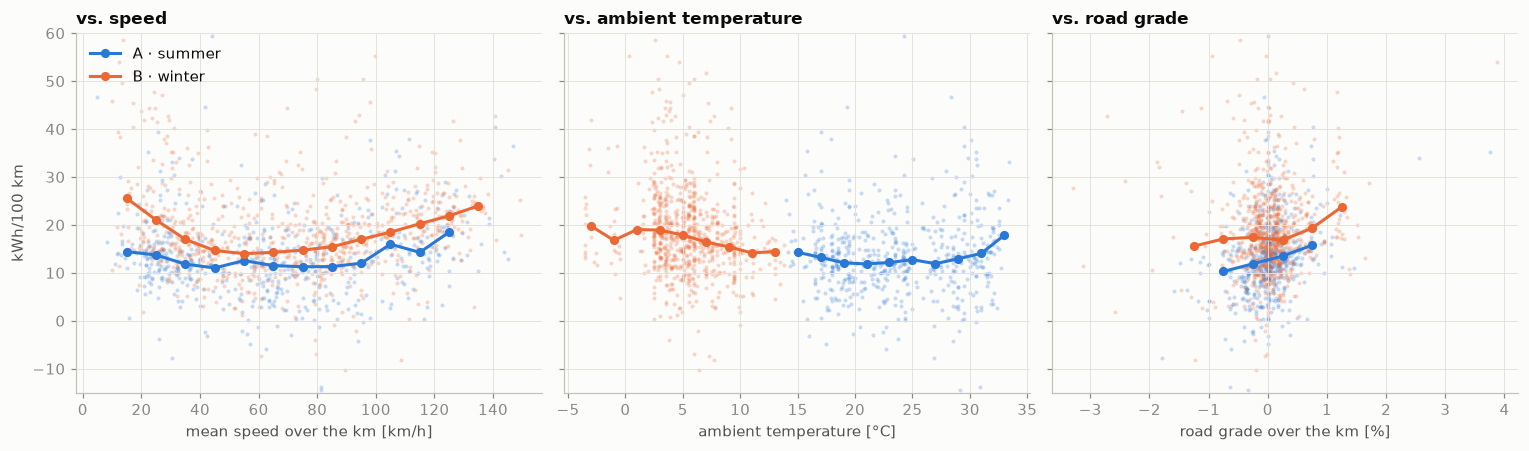

Spearman correlation with kWh/100 km (all bins):


speed_mean_kmh    0.10
ambient_temp_c   -0.31
grade_pct         0.16
heater_kw         0.39
speed_std_kmh     0.06


In [4]:
def binned_median(x: pd.Series, y: pd.Series, edges: np.ndarray, min_n: int = 10) -> pd.DataFrame:
    """Median of y within each x-bin, keeping bins with at least min_n points."""
    cut = pd.cut(x, edges)
    g = y.groupby(cut, observed=True).agg(["median", "size"])
    g = g[g["size"] >= min_n]
    return pd.DataFrame({"x": [iv.mid for iv in g.index], "median": g["median"].to_numpy(), "n": g["size"].to_numpy()})

panels = [
    ("speed_mean_kmh", "mean speed over the km [km/h]", np.arange(0, 161, 10)),
    ("ambient_temp_c", "ambient temperature [°C]", np.arange(-4, 36, 2)),
    ("grade_pct", "road grade over the km [%]", np.arange(-3, 3.01, 0.5)),
]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (col, label, edges) in zip(axes, panels):
    for s in ["A", "B"]:
        sub = bins[bins.series == s]
        ax.scatter(sub[col], sub.kwh_per_100km, s=7, alpha=0.25, color=SERIES_COLOR[s], linewidths=0)
        m = binned_median(sub[col], sub.kwh_per_100km, edges)
        ax.plot(m.x, m["median"], color=SERIES_COLOR[s], marker="o", ms=5, label=SERIES_LABEL[s])
    ax.set_xlabel(label)
axes[0].set_ylabel("kWh/100 km"); axes[0].set_ylim(-15, 60); axes[0].legend(loc="upper left")
axes[0].set_title("vs. speed"); axes[1].set_title("vs. ambient temperature"); axes[2].set_title("vs. road grade")
fig.tight_layout(); fig.savefig(FIG_DIR / "consumption_vs_conditions.png", bbox_inches="tight"); plt.show()

print("Spearman correlation with kWh/100 km (all bins):")
print(bins[["speed_mean_kmh", "ambient_temp_c", "grade_pct", "heater_kw", "speed_std_kmh"]]
      .corrwith(bins.kwh_per_100km, method="spearman").round(2).to_string())

### 2b. Is the winter penalty just a speed difference?

Temperature and speed are confounded if winter trips happen to be driven differently. Comparing the two series
**within the same speed band** removes that effect. Also shown: how much of the battery power goes to the heater.

In [5]:
band = pd.cut(bins.speed_mean_kmh, [0, 30, 50, 70, 90, 110, 160])
tab = bins.pivot_table(index=band, columns="series", values="kwh_per_100km", aggfunc="median", observed=True)
tab["n_A"] = bins[bins.series == "A"].groupby(band[bins.series == "A"], observed=True).size()
tab["n_B"] = bins[bins.series == "B"].groupby(band[bins.series == "B"], observed=True).size()
tab["winter / summer"] = tab["B"] / tab["A"]
tab.index.name = "speed band [km/h]"
display(tab.round(2))

# Heater share of battery energy, over trips with a valid heater signal. Trips failing the heater
# plausibility check (data card) have heater_power_kw = NaN and are left out of both sums.
valid = clean[clean.heater_power_kw.notna()]
print("trips without a valid heater signal:", sorted(set(clean.trip_id) - set(valid.trip_id)))
heat = (valid.heater_power_kw * SAMPLE_PERIOD_S / 3600).groupby(valid.series).sum()
batt = (valid.power_draw_kw.clip(lower=0) * SAMPLE_PERIOD_S / 3600).groupby(valid.series).sum()
share = pd.DataFrame({"heater kWh": heat, "battery kWh discharged": batt, "heater share": heat / batt})
share.index = share.index.map(SERIES_LABEL)
display(share.round(3))

series,A,B,n_A,n_B,winter / summer
speed band [km/h],,,,,
"(0, 30]",14.03,21.78,121,99,1.55
"(30, 50]",11.33,15.67,93,145,1.38
"(50, 70]",11.69,14.27,113,115,1.22
"(70, 90]",11.28,15.41,86,159,1.37
"(90, 110]",13.98,17.60,66,106,1.26
"(110, 160]",16.35,21.86,70,133,1.34


trips without a valid heater signal: ['TripA05', 'TripA06', 'TripA13']


,heater kWh,battery kWh discharged,heater share
series,,,
A · summer,3.41,87.86,0.04
B · winter,26.49,163.85,0.16


## 3. How noisy is SoC-based consumption?

The brief suggests a target like **%SoC per km over the next N km**. SoC is reported in coarse steps, so over a short
distance the SoC drop is dominated by rounding. Energy (integrated V·I) has no such rounding. Below, the same trips
are cut into bins of 1, 2, 5 and 10 km; for each bin we convert energy to "%SoC-equivalent" with the data-card
ratio and measure how far the SoC-based value is from it.

,bins,trips with ≥1 bin,"corr(SoC-rate, energy-rate)",median |diff| / median rate,90th pct |diff| / median rate
bin [km],,,,,
1,1306,70,0.95,0.05,0.15
2,638,70,0.96,0.04,0.11
5,232,67,0.98,0.03,0.09
10,95,62,0.98,0.02,0.09


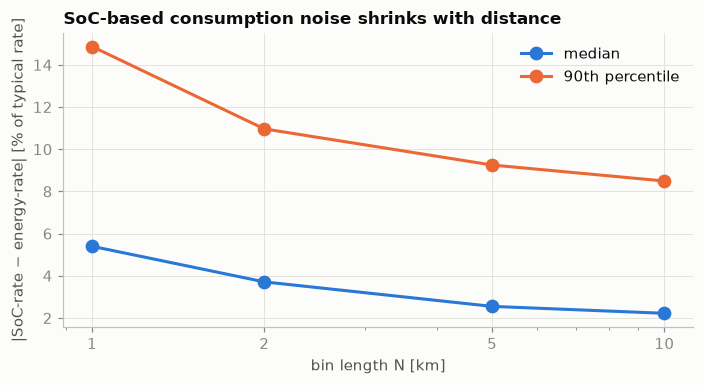

In [6]:
KWH_PER_PCT = 0.2282  # from data/DATA_CARD.md
rows = []
for km in [1, 2, 5, 10]:
    b = distance_bins(clean, bin_km=km)
    soc_rate = b.soc_per_km
    energy_rate = b.energy_kwh / KWH_PER_PCT / b.distance_km  # %SoC-equivalent per km
    rel = (soc_rate - energy_rate).abs() / energy_rate.abs().median()
    rows.append({"bin [km]": km, "bins": len(b), "trips with ≥1 bin": b.trip_id.nunique(),
                 "corr(SoC-rate, energy-rate)": np.corrcoef(soc_rate, energy_rate)[0, 1],
                 "median |diff| / median rate": rel.median(), "90th pct |diff| / median rate": rel.quantile(0.9)})
noise = pd.DataFrame(rows).set_index("bin [km]")
display(noise.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(noise.index, noise["median |diff| / median rate"] * 100, marker="o", ms=8, color="#2a78d6", label="median")
ax.plot(noise.index, noise["90th pct |diff| / median rate"] * 100, marker="o", ms=8, color="#eb6834", label="90th percentile")
ax.set_xscale("log"); ax.set_xticks(noise.index); ax.set_xticklabels(noise.index)
ax.set_xlabel("bin length N [km]"); ax.set_ylabel("|SoC-rate − energy-rate| [% of typical rate]")
ax.set_title("SoC-based consumption noise shrinks with distance"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "soc_noise_vs_bin_length.png", bbox_inches="tight"); plt.show()

## Summary

The checkpoint write-up (Phase 1) pulls its numbers from the printed outputs above. Re-running this notebook
top-to-bottom reproduces every figure in `figures/eda/`.